# Outcome vs Uncertainty — 1 BTG

Plots:
1. T1 BCAS death rate vs selected uncertainty
2. Fraction of T2 treated within NATO timeline vs selected uncertainty

In [50]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── CONFIGURATION ────────────────────────────────────────────────────────────
FOLDER_NAME = "20260604_183236_scenario_2btg_1ccp_each"
UNCERTAINTY = "ccp_r1_inter_bn_min"   # <-- change this to any uncertainty column
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
levels = sorted(df[UNCERTAINTY].unique())
print(f"Loaded {len(df)} runs  |  {UNCERTAINTY} levels: {levels}")

Loaded 1000 runs  |  ccp_r1_inter_bn_min levels: [np.int64(5), np.int64(15), np.int64(30), np.int64(45), np.int64(60), np.int64(75), np.int64(90), np.int64(105), np.int64(120), np.int64(135)]


In [51]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec

def median_ci(vals, n_boot=1000, alpha=0.05):
    """Bootstrap 95% CI half-width for the median."""
    if len(vals) < 2:
        return np.nan
    rng = np.random.default_rng(42)
    boots = np.array([np.median(rng.choice(vals, size=len(vals))) for _ in range(n_boot)])
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return (hi - lo) / 2

def plot_diagnostic_matrix(rows, triage_label):
    """
    Heatmap with dual colour scales.
    Each row is (label, column_name) or (label, column_name, agg)
    where agg is 'median' (default), 'q25', or 'q75'.
    Rows whose label starts with 'Mortality' use Reds; all others use Blues.
    """
    rows_norm = [(r[0], r[1], r[2] if len(r) > 2 else "median") for r in rows]

    matrix = pd.DataFrame(index=[r[0] for r in rows_norm], columns=[str(lv) for lv in levels], dtype=float)
    ci_mat = pd.DataFrame(index=[r[0] for r in rows_norm], columns=[str(lv) for lv in levels], dtype=float)

    for label, col, agg in rows_norm:
        for lv in levels:
            vals = df.loc[df[UNCERTAINTY] == lv, col].dropna().values
            if len(vals) == 0:
                matrix.loc[label, str(lv)] = np.nan
                ci_mat.loc[label, str(lv)] = np.nan
                continue
            if agg == "q25":
                matrix.loc[label, str(lv)] = np.percentile(vals, 25)
            elif agg == "q75":
                matrix.loc[label, str(lv)] = np.percentile(vals, 75)
            else:
                matrix.loc[label, str(lv)] = np.median(vals)
            ci_mat.loc[label, str(lv)] = median_ci(vals)

    mort_idx = [i for i, (lab, _, __) in enumerate(rows_norm) if lab.startswith("Mortality")]
    wait_idx = [i for i in range(len(rows_norm)) if i not in mort_idx]

    vals_f = matrix.values.astype(float)
    wait_vals = vals_f[wait_idx, :].flatten()
    mort_vals = vals_f[mort_idx, :].flatten()
    norm_wait = Normalize(vmin=np.nanmin(wait_vals), vmax=np.nanmax(wait_vals))
    norm_mort = Normalize(vmin=np.nanmin(mort_vals), vmax=np.nanmax(mort_vals))
    cmap_wait = plt.cm.Blues
    cmap_mort = plt.cm.Reds

    n_rows, n_cols = vals_f.shape

    fig = plt.figure(figsize=(max(9, n_cols * 1.5 + 2), n_rows * 0.85 + 1.5))
    gs = gridspec.GridSpec(2, 2, width_ratios=[1, 0.03], height_ratios=[1, 1],
                           wspace=0.05, hspace=0.08)
    ax = fig.add_subplot(gs[:, 0])
    cax_w = fig.add_subplot(gs[0, 1])
    cax_m = fig.add_subplot(gs[1, 1])

    for i in range(n_rows):
        is_mort = i in mort_idx
        norm = norm_mort if is_mort else norm_wait
        cmap = cmap_mort if is_mort else cmap_wait
        for j in range(n_cols):
            v = vals_f[i, j]
            color = cmap(norm(v)) if not np.isnan(v) else (0.95, 0.95, 0.95, 1)
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=color, edgecolor="white", lw=1.5))
            if not np.isnan(v):
                ci = ci_mat.iloc[i, j]
                txt = f"{v:.3f}\n(±{ci:.3f})" if not np.isnan(ci) else f"{v:.3f}"
                brightness = 0.299 * color[0] + 0.587 * color[1] + 0.114 * color[2]
                ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                        color="white" if brightness < 0.55 else "black")

    ax.set_xlim(-0.5, n_cols - 0.5)
    ax.set_ylim(n_rows - 0.5, -0.5)
    ax.set_xticks(range(n_cols))
    ax.set_xticklabels([str(lv) for lv in levels])
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels([r[0] for r in rows_norm])
    ax.set_xlabel(UNCERTAINTY)
    ax.set_title(f"{triage_label} Diagnostic Matrix — per {UNCERTAINTY} level")

    fig.colorbar(ScalarMappable(norm=norm_wait, cmap=cmap_wait), cax=cax_w, label="Wait (min)")
    fig.colorbar(ScalarMappable(norm=norm_mort, cmap=cmap_mort), cax=cax_m, label="Mortality rate")

    plt.tight_layout()
    plt.show()
    print(matrix.to_string(float_format="%.4f"))
    return matrix

def boxplot_by_uncertainty(outcome, ylabel, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))
    data = [df.loc[df[UNCERTAINTY] == lv, outcome].dropna().values for lv in levels]
    bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)
    for patch in bp["boxes"]:
        patch.set_facecolor("steelblue")
        patch.set_alpha(0.7)
    for i, d in enumerate(data):
        if len(d) > 0:
            med = np.median(d)
            ax.text(i + 1, med, f"  {med:.3f}", va="center", fontsize=9, fontweight="bold")
    ax.set_xlabel(UNCERTAINTY)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    return ax

## 1. Fraction of Facility Pooling (Cross-BN)

C:\Users\User\AppData\Local\Temp\ipykernel_11028\3802913015.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


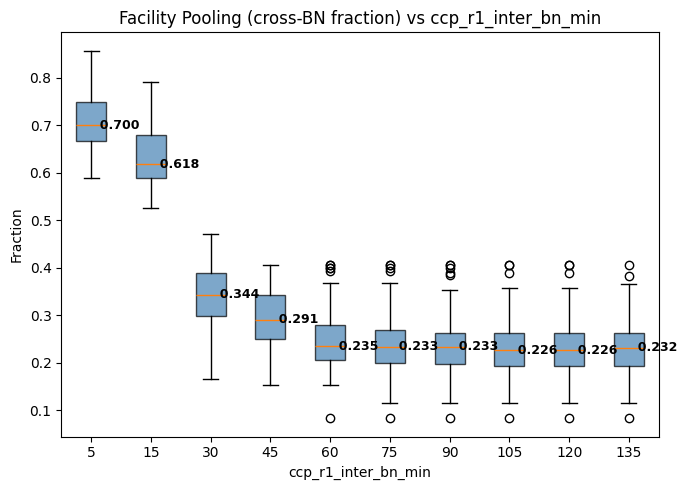

                      mean  median    std    min    max
ccp_r1_inter_bn_min                                    
5                   0.7033  0.7000 0.0577 0.5882 0.8571
15                  0.6343  0.6183 0.0610 0.5263 0.7917
30                  0.3381  0.3438 0.0618 0.1667 0.4706
45                  0.2939  0.2906 0.0600 0.1538 0.4062
60                  0.2480  0.2353 0.0643 0.0833 0.4062
75                  0.2387  0.2333 0.0641 0.0833 0.4062
90                  0.2379  0.2333 0.0638 0.0833 0.4062
105                 0.2331  0.2265 0.0607 0.0833 0.4062
120                 0.2341  0.2265 0.0607 0.0833 0.4062
135                 0.2341  0.2321 0.0595 0.0833 0.4062


In [52]:
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_by_uncertainty("frac_facility_cross_bn", "Fraction", f"Facility Pooling (cross-BN fraction) vs {UNCERTAINTY}", ax=ax)
plt.tight_layout()
plt.show()

print(df.groupby(UNCERTAINTY)["frac_facility_cross_bn"].agg(["mean", "median", "std", "min", "max"]).to_string(float_format="%.4f"))

C:\Users\User\AppData\Local\Temp\ipykernel_11028\3802913015.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


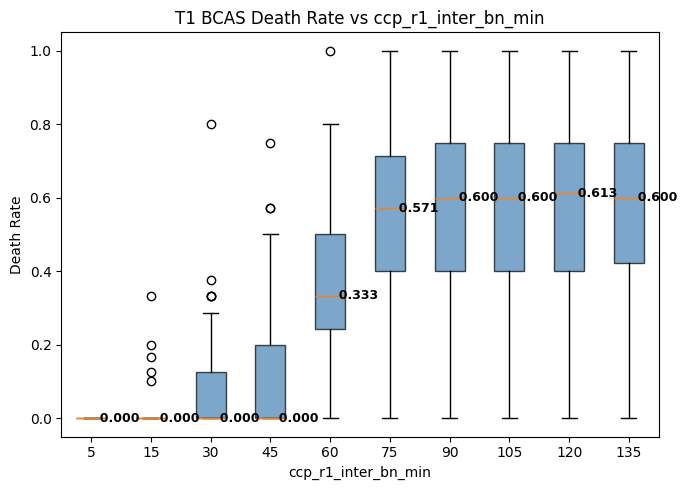

                      mean  median    std    min    max
ccp_r1_inter_bn_min                                    
5                   0.0000  0.0000 0.0000 0.0000 0.0000
15                  0.0092  0.0000 0.0445 0.0000 0.3333
30                  0.0670  0.0000 0.1274 0.0000 0.8000
45                  0.1142  0.0000 0.1722 0.0000 0.7500
60                  0.3726  0.3333 0.2218 0.0000 1.0000
75                  0.5472  0.5714 0.2601 0.0000 1.0000
90                  0.5586  0.6000 0.2619 0.0000 1.0000
105                 0.5578  0.6000 0.2606 0.0000 1.0000
120                 0.5662  0.6125 0.2609 0.0000 1.0000
135                 0.5625  0.6000 0.2577 0.0000 1.0000


In [53]:
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_by_uncertainty("death_rate_T1_BCAS", "Death Rate", f"T1 BCAS Death Rate vs {UNCERTAINTY}", ax=ax)
plt.tight_layout()
plt.show()

print(df.groupby(UNCERTAINTY)["death_rate_T1_BCAS"].agg(["mean", "median", "std", "min", "max"]).to_string(float_format="%.4f"))

## 2. Fraction of T2 Within NATO Timeline

C:\Users\User\AppData\Local\Temp\ipykernel_11028\3802913015.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


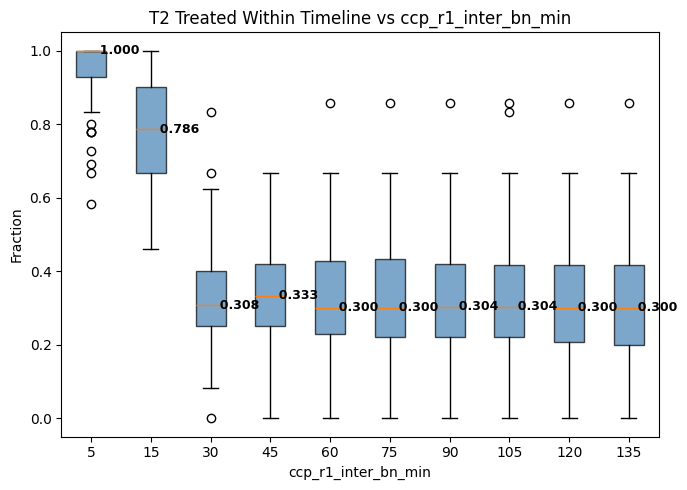

                      mean  median    std    min    max
ccp_r1_inter_bn_min                                    
5                   0.9548  1.0000 0.0856 0.5833 1.0000
15                  0.7867  0.7857 0.1527 0.4615 1.0000
30                  0.3304  0.3077 0.1385 0.0000 0.8333
45                  0.3424  0.3333 0.1325 0.0000 0.6667
60                  0.3348  0.3000 0.1540 0.0000 0.8571
75                  0.3339  0.3000 0.1601 0.0000 0.8571
90                  0.3302  0.3038 0.1591 0.0000 0.8571
105                 0.3305  0.3038 0.1630 0.0000 0.8571
120                 0.3249  0.3000 0.1604 0.0000 0.8571
135                 0.3223  0.3000 0.1598 0.0000 0.8571


In [54]:
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_by_uncertainty("frac_t2_within_timeline", "Fraction", f"T2 Treated Within Timeline vs {UNCERTAINTY}", ax=ax)
plt.tight_layout()
plt.show()

print(df.groupby(UNCERTAINTY)["frac_t2_within_timeline"].agg(["mean", "median", "std", "min", "max"]).to_string(float_format="%.4f"))

## 3. Diagnostic Matrix — T1

C:\Users\User\AppData\Local\Temp\ipykernel_11028\3802913015.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


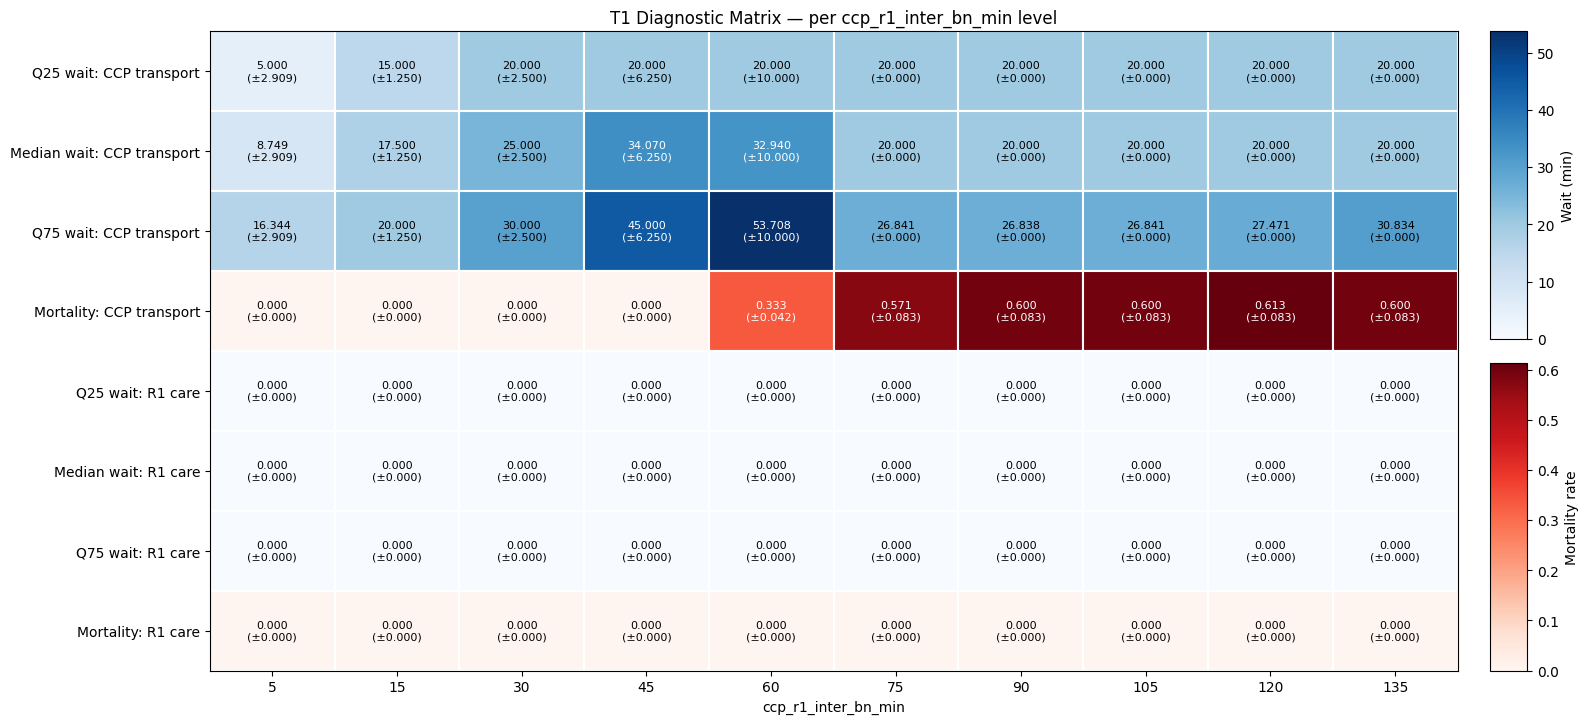

                                 5      15      30      45      60      75      90     105     120     135
Q25 wait: CCP transport     5.0000 15.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000
Median wait: CCP transport  8.7489 17.5000 25.0000 34.0703 32.9396 20.0000 20.0000 20.0000 20.0000 20.0000
Q75 wait: CCP transport    16.3440 20.0000 30.0000 45.0000 53.7080 26.8412 26.8382 26.8412 27.4709 30.8341
Mortality: CCP transport    0.0000  0.0000  0.0000  0.0000  0.3333  0.5714  0.6000  0.6000  0.6125  0.6000
Q25 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Median wait: R1 care        0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Q75 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Mortality: R1 care          0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000


,5,15,30,45,60,75,90,105,120,135
Q25 wait: CCP transport,5.000000,15.0,20.0,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.00000
Median wait: CCP transport,8.748915,17.5,25.0,34.070299,32.939646,20.000000,20.000000,20.000000,20.000000,20.00000
Q75 wait: CCP transport,16.344023,20.0,30.0,45.000000,53.707959,26.841152,26.838208,26.841152,27.470863,30.83406
Mortality: CCP transport,0.000000,0.0,0.0,0.000000,0.333333,0.571429,0.600000,0.600000,0.612500,0.60000
Q25 wait: R1 care,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
Median wait: R1 care,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
Q75 wait: R1 care,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
Mortality: R1 care,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000


In [55]:
t1_rows = [
    ("Q25 wait: CCP transport",     "median_wait_ccp_transport_T1", "q25"),
    ("Median wait: CCP transport",  "median_wait_ccp_transport_T1"),
    ("Q75 wait: CCP transport",     "median_wait_ccp_transport_T1", "q75"),
    ("Mortality: CCP transport",    "mortality_ccp_transport_T1"),
    ("Q25 wait: R1 care",           "median_wait_r1_care_T1", "q25"),
    ("Median wait: R1 care",        "median_wait_r1_care_T1"),
    ("Q75 wait: R1 care",           "median_wait_r1_care_T1", "q75"),
    ("Mortality: R1 care",          "mortality_r1_care_T1"),
    # ("Q25 wait: R1 transport",      "median_wait_r1_transport_T1", "q25"),
    # ("Median wait: R1 transport",   "median_wait_r1_transport_T1"),
    # ("Q75 wait: R1 transport",      "median_wait_r1_transport_T1", "q75"),
    # ("Mortality: R1 transport",     "mortality_r1_transport_T1"),
    # ("Q25 wait: R2 care",           "median_wait_r2_care_T1", "q25"),
    # ("Median wait: R2 care",        "median_wait_r2_care_T1"),
    # ("Q75 wait: R2 care",           "median_wait_r2_care_T1", "q75"),
    # ("Mortality: R2 care",          "mortality_r2_care_T1"),
]

plot_diagnostic_matrix(t1_rows, "T1")

## 4. Diagnostic Matrix — T2

C:\Users\User\AppData\Local\Temp\ipykernel_11028\3802913015.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


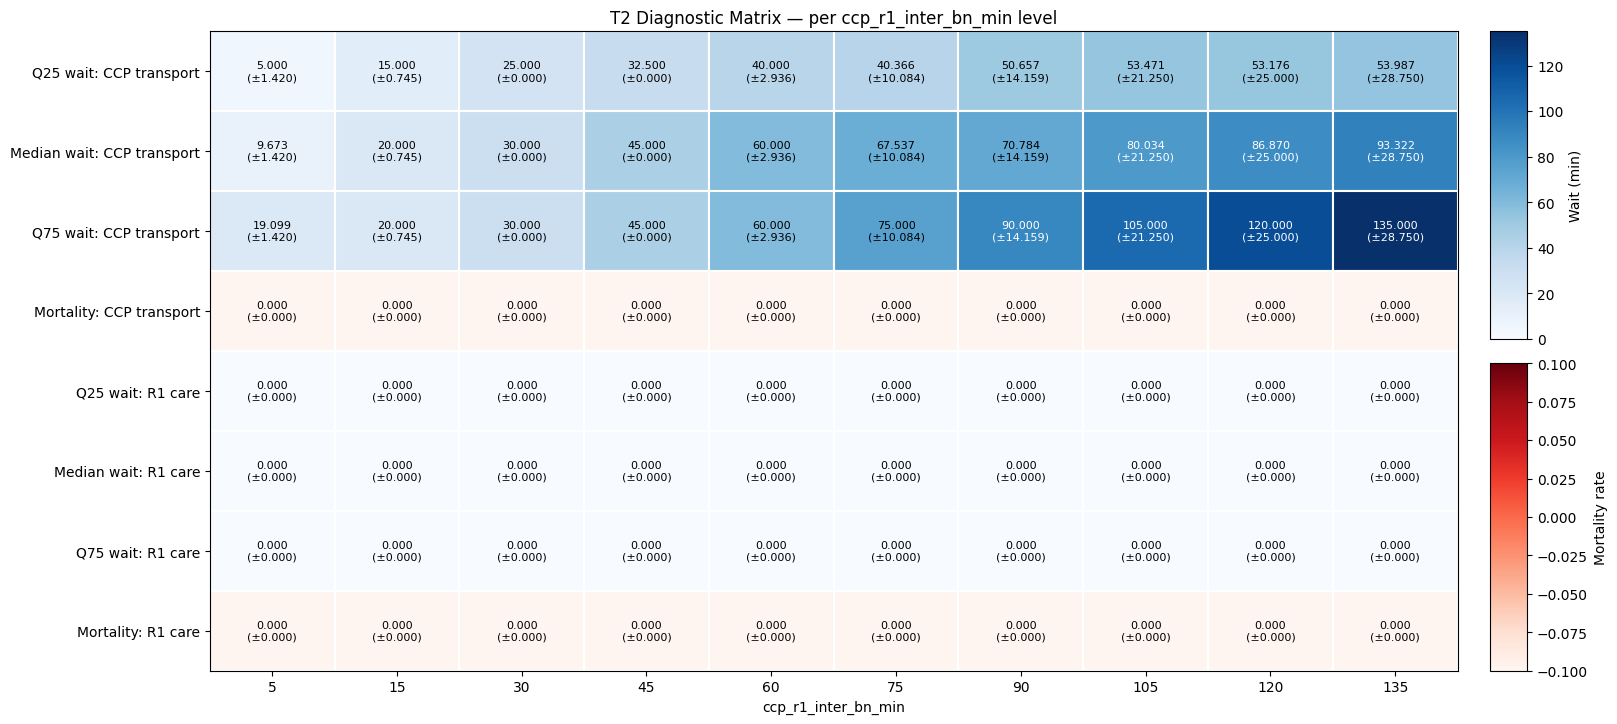

                                 5      15      30      45      60      75      90      105      120      135
Q25 wait: CCP transport     5.0000 15.0000 25.0000 32.5000 40.0000 40.3664 50.6574  53.4706  53.1756  53.9869
Median wait: CCP transport  9.6731 20.0000 30.0000 45.0000 60.0000 67.5374 70.7840  80.0342  86.8697  93.3218
Q75 wait: CCP transport    19.0989 20.0000 30.0000 45.0000 60.0000 75.0000 90.0000 105.0000 120.0000 135.0000
Mortality: CCP transport    0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0000   0.0000
Q25 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0000   0.0000
Median wait: R1 care        0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0000   0.0000
Q75 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0000   0.0000
Mortality: R1 care          0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   0.0000   0.0000   0.0000


,5,15,30,45,60,75,90,105,120,135
Q25 wait: CCP transport,5.000000,15.0,25.0,32.5,40.0,40.366430,50.657442,53.470630,53.175615,53.986917
Median wait: CCP transport,9.673089,20.0,30.0,45.0,60.0,67.537417,70.783962,80.034157,86.869734,93.321847
Q75 wait: CCP transport,19.098859,20.0,30.0,45.0,60.0,75.000000,90.000000,105.000000,120.000000,135.000000
Mortality: CCP transport,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
Q25 wait: R1 care,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
Median wait: R1 care,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
Q75 wait: R1 care,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
Mortality: R1 care,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000


In [56]:
t2_rows = [
    ("Q25 wait: CCP transport",     "median_wait_ccp_transport_T2", "q25"),
    ("Median wait: CCP transport",  "median_wait_ccp_transport_T2"),
    ("Q75 wait: CCP transport",     "median_wait_ccp_transport_T2", "q75"),
    ("Mortality: CCP transport",    "mortality_ccp_transport_T2"),
    ("Q25 wait: R1 care",           "median_wait_r1_care_T2", "q25"),
    ("Median wait: R1 care",        "median_wait_r1_care_T2"),
    ("Q75 wait: R1 care",           "median_wait_r1_care_T2", "q75"),
    ("Mortality: R1 care",          "mortality_r1_care_T2"),
    # ("Q25 wait: R1 transport",      "median_wait_r1_transport_T2", "q25"),
    # ("Median wait: R1 transport",   "median_wait_r1_transport_T2"),
    # ("Q75 wait: R1 transport",      "median_wait_r1_transport_T2", "q75"),
    # ("Mortality: R1 transport",     "mortality_r1_transport_T2"),
    # ("Q25 wait: R2 care",           "median_wait_r2_care_T2", "q25"),
    # ("Median wait: R2 care",        "median_wait_r2_care_T2"),
    # ("Q75 wait: R2 care",           "median_wait_r2_care_T2", "q75"),
    # ("Mortality: R2 care",          "mortality_r2_care_T2"),
]

plot_diagnostic_matrix(t2_rows, "T2")